In [34]:
import torch

In [35]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce GTX 1080'

In [36]:
torch.cuda.is_available()

True

In [37]:

import torch


# Dataset 

In [38]:

import numpy as np
import glob
import time

import cv2



def load_file(filename):
    arrays = np.load(filename)
    #arrays = np.stack([cv2.cvtColor(arrays[_], cv2.COLOR_BGR2GRAY)
     #                 for _ in range(30)], axis=0)
    #arrays = arrays / 255.
    return arrays

In [39]:
class MyDataset():
    def __init__(self, folds, path):
        self.folds = folds
        self.path = path
        with open(r'F:\VisualSpeech\dataset\l.txt') as myfile:
            lines = myfile.read().splitlines()
        self.data_dir = [self.path + item for item in lines]
        self.data_files = glob.glob(self.path+'*/'+self.folds+'/*.npy')
        self.labels = {}
        for idx, label in enumerate(list(open(r'F:\VisualSpeech\dataset\l.txt'))):
            label = label.strip()
            self.labels[label] = idx

    def __getitem__(self, idx):
        inputs = load_file(self.data_files[idx])
        labels = self.labels[self.data_files[idx].split('\\')[-1].split('_')[0]]
        #print("Label from file path:", labels)
        return inputs, labels

    def __len__(self):
        return len(self.data_files)


# cvtransforms

In [40]:
import random
import cv2
import numpy as np


def CenterCrop(batch_img, size):
    w, h = batch_img[0][0].shape[1], batch_img[0][0].shape[0]
    th, tw = size
    img = np.zeros((len(batch_img), len(batch_img[0]), th, tw))
    for i in range(len(batch_img)):
        x1 = int(round((w - tw))/2.)
        y1 = int(round((h - th))/2.)
        img[i] = batch_img[i, :, y1:y1+th, x1:x1+tw]
    return img

In [41]:
def RandomCrop(batch_img, size):
    w, h = batch_img[0][0].shape[1], batch_img[0][0].shape[0]
    th, tw = size
    img = np.zeros((len(batch_img), len(batch_img[0]), th, tw))
    for i in range(len(batch_img)):
        x1 = random.randint(0, 8)
        y1 = random.randint(0, 8)
        img[i] = batch_img[i, :, y1:y1+th, x1:x1+tw]
    return img

In [42]:

def HorizontalFlip(batch_img):
    for i in range(len(batch_img)):
        if random.random() > 0.5:
            for j in range(len(batch_img[i])):
                batch_img[i][j] = cv2.flip(batch_img[i][j], 1)
    return batch_img


def ColorNormalize(batch_img):
    mean = 0.413621
    std = 0.1700239
    batch_img = (batch_img - mean) / std
    return batch_img



# Model

In [43]:

import math
import numpy as np


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable


def conv3x3(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=1, bias=False)

In [44]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock, self).__init__()
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual
        out = self.relu(out)

        return out

In [45]:
class ExceptionModel(nn.Module):

    def __init__(self, block, layers, num_classes=3):
        self.inplanes = 64
        super(ExceptionModel, self).__init__()
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.gloablavgpool = nn.AdaptiveAvgPool2d((1,1))
        self.bn = nn.BatchNorm1d(512)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()
            elif isinstance(m, nn.BatchNorm1d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes * block.expansion
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gloablavgpool(x)
        
        
        
        x= x.view(x.size(0),-1)
        x = self.bn(x)



        return x

In [46]:
class GRU(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, every_frame=True):
        super(GRU, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.every_frame = every_frame
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size*2, num_classes)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        self.gru.flatten_parameters()
        h0 = Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
        out, _ = self.gru(x, h0)
        
        out = self.dropout(out).mean(1)
        out = self.fc(out)

        return out

In [47]:
class Lipreading(nn.Module):
    def __init__(self, mode, inputDim=256, hiddenDim=1024, nClasses=3, frameLen=30, every_frame=True):
        super(Lipreading, self).__init__()
        self.mode = mode
        self.inputDim = inputDim
        self.hiddenDim = hiddenDim
        self.nClasses = nClasses
        self.frameLen = 30
        self.every_frame = every_frame
        self.nLayers = 3
        # frontend3D
        self.frontend3D = nn.Sequential(
                nn.Conv3d(1, 64, kernel_size=(5, 7, 7), stride=(1, 2, 2), padding=(2, 3, 3), bias=False),
                nn.BatchNorm3d(64),
                nn.ReLU(True),
                nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1))
                )
        

        self.ExceptionModel = ExceptionModel(BasicBlock, [2, 2, 2, 2], num_classes=self.inputDim)
        self.dropout = nn.Dropout(0.2)



        self.gru = GRU(self.inputDim, self.hiddenDim, self.nLayers, self.nClasses, self.every_frame)
            # initialize
        self._initialize_weights()

    def forward(self, x):
        x = self.frontend3D(x)
        x = x.transpose(1, 2)
        x = x.contiguous()
        x = x.view(-1, 64, x.size(3), x.size(4))
        x = self.ExceptionModel(x)

        x = self.dropout(x)

        x = x.view(-1, self.frameLen, self.inputDim)
        x = self.gru(x)

        return x

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.kernel_size[2] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
                if m.bias is not None:
                    m.bias.data.zero_()

            elif isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
                if m.bias is not None:
                    m.bias.data.zero_()

            elif isinstance(m, nn.Conv1d):
                n = m.kernel_size[0] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
                if m.bias is not None:
                    m.bias.data.zero_()

            elif isinstance(m, nn.BatchNorm3d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

            elif isinstance(m, nn.BatchNorm1d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

In [48]:

!pip install torchsummary

In [49]:
if (__name__ == '__main__'):
    import torchsummary
    model = ExceptionModel(BasicBlock, [3,4,6,3], num_classes=3)
    #torchsummary.summary(model,(64,22,22),device='cpu')

# Main

In [50]:
import os
import time
import random
import logging
import argparse
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

#from model import *
#from dataset import *
#from cvtransforms import *

SEED = 1
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)

In [51]:
import numpy as np
import torch
import torchvision
from torchvision import datasets, models, transforms
import torch.utils.data as data
#from torch.utils.tensorboard import SummaryWriter
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
#from nets import *
import time, os, copy, argparse
import multiprocessing
from torchsummary import summary
#from matplotlib import pyplot as plt

In [52]:
parser = argparse.ArgumentParser(description='Pytorch-GLMIM-LRW')
parser.add_argument('--nClasses', default=3, type=int, help='the number of classes')
#path : path to model, when you start Baseline, it's empty, otherwise it would load the model.
parser.add_argument('--path', default=r'', type=str, help='path to Baseline, empty for training')
parser.add_argument('--dataset', default=r'F:/VisualSpeech/dataset/3class/', type=str, help='path/to/lrw/roi_80_116_175_211_npy_gray/')
parser.add_argument('--mode', default='Baseline', type=str)
parser.add_argument('--every-frame', default=True, action='store_false', help='predicition based on every frame')
parser.add_argument('--lr', default=1e-4, type=float, help='initial learning rate')
parser.add_argument('--batch-size', default=8, type=int, help='mini-batch size')
#parser.add_argument('--workers', default=5, type=int, help='number of data loading workers')
parser.add_argument('--epochs', default=12, type=int, help='number of total epochs')
parser.add_argument('--s_epochs', default=1, type=int, help='number of start epochs')
parser.add_argument('--interval', default=40, type=int, help='display interval')
parser.add_argument('--test', default=False, action='store_false', help='perform on the test phase')


_StoreFalseAction(option_strings=['--test'], dest='test', nargs=0, const=False, default=False, type=None, choices=None, required=False, help='perform on the test phase', metavar=None)

In [53]:

args = parser.parse_args([])
print(args)

Namespace(nClasses=3, path='', dataset='F:/VisualSpeech/dataset/3class/', mode='Baseline', every_frame=True, lr=0.0001, batch_size=8, epochs=12, s_epochs=1, interval=40, test=False)


In [54]:
torch.cuda.is_available()
if torch.cuda.is_available():
    torch.set_default_tensor_type('torch.cuda.FloatTensor')

In [55]:

def data_loader(args):
    dsets = {x: MyDataset(x, args.dataset) for x in ['train','val', 'test']}
    dset_loaders = {x: DataLoader(dsets[x], batch_size=args.batch_size, shuffle=True,generator=torch.Generator(device="cuda")) for x in ['train', 'val', 'test']}
    dset_sizes = {x: len(dsets[x]) for x in ['train', 'val', 'test']}
    print('\nStatistics: train: {}, val: {}, test: {}'.format(dset_sizes['train'], dset_sizes['val'], dset_sizes['test']))
    return dset_loaders, dset_sizes

In [56]:
def reload_model(model, logger, path=""):
    if not bool(path):
        logger.info('train from scratch')
        return
    own_state = model.state_dict()
    state_dict = torch.load(path)
    for name, param in state_dict.items():
        if name not in own_state:
            print('layer {} skip, not exist'.format(name))
            continue
        if isinstance(param, nn.Parameter):
            param = param.data
        if own_state[name].shape != param.shape:
            print('layer {} skip, shape not same'.format(name))
            continue
        own_state[name].copy_(param)

In [57]:
def showLR(optimizer):
    lr = []
    for param_group in optimizer.param_groups:
        lr += [param_group['lr']]
    return lr

<h1> new test, train, test_adam

In [25]:
import time
import numpy as np


def train(model, dset_loaders, criterion, epoch, phase, optimizer, args, logger, use_gpu):
    model.train()
    logger.info('-' * 2)
    logger.info('Epoch {}/{}'.format(epoch, args.epochs - 1))
    logger.info('Current Learning rate: {}'.format(showLR(optimizer)))

    running_loss, running_corrects, running_all = 0., 0., 0.
    since = time.time()
    last_time_batch_idx = -1
    for batch_idx, (inputs, targets) in enumerate(dset_loaders[phase]):
        batch_img = RandomCrop(inputs.cpu().numpy(), (90, 90))
        batch_img = ColorNormalize(batch_img)
        batch_img = HorizontalFlip(batch_img)

        batch_img = np.reshape(batch_img, (batch_img.shape[0], batch_img.shape[1], batch_img.shape[2], batch_img.shape[3], 1))
        inputs = torch.from_numpy(batch_img)
        inputs = inputs.float().permute(0, 4, 1, 2, 3).contiguous()
        if use_gpu:
            inputs = inputs.cuda()
            targets = targets.cuda()
        optimizer.zero_grad()
        outputs = model(inputs)
        _, preds = torch.max(outputs.data, 1)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        # statistics
        running_loss += loss.item() * inputs.size(0)
        batch_correct = (preds == targets.data).sum().item()
        running_corrects += batch_correct
        running_all += len(inputs)

        if batch_idx % args.interval == 0 or (batch_idx == len(dset_loaders[phase])-1):
            logger.info('Process:  [({:.0f}%)]\tLoss batch: {:.4f}\tLoss total: {:.4f}\tAcc batch:{:.4f}\tAcc total:{:.4f}\tEstimated time:{:5.0f}s'.format(
             
                100. * batch_idx / (len(dset_loaders[phase])-1),
                float(loss),
                float(running_loss) / running_all,
                float(batch_correct) / len(inputs),
                float(running_corrects) / running_all,
                (time.time() - since) / (batch_idx - last_time_batch_idx) * (len(dset_loaders[phase]) - batch_idx - 1))),
            last_time_batch_idx = batch_idx
            since = time.time()

    loss_epoch =  float(running_loss) / len(dset_loaders[phase].dataset)
    acc_epoch = float(running_corrects) / len(dset_loaders[phase].dataset)

    logger.info('{} Epoch:\t{:2}\tLoss: {:.4f}\tAcc:{:.4f}\n'.format(
        phase,
        epoch,
        loss_epoch,
        acc_epoch))
    
    return loss_epoch, acc_epoch

In [26]:
def test2(model, dset_loaders, criterion, epoch, phase, args, logger, use_gpu, save=True):
    model.eval()
    with torch.no_grad():
        running_loss, running_corrects, running_all = 0., 0., 0.
        since = time.time()
        last_time_batch_idx = -1
        all_preds = []
        all_labels = []
        for batch_idx, (inputs, targets) in enumerate(dset_loaders[phase]):
            batch_img = CenterCrop(inputs.cpu().numpy(), (90, 90))
            batch_img = ColorNormalize(batch_img)

            batch_img = np.reshape(batch_img, (batch_img.shape[0], batch_img.shape[1], batch_img.shape[2], batch_img.shape[3], 1))
            inputs = torch.from_numpy(batch_img)
            inputs = inputs.float().permute(0, 4, 1, 2, 3).contiguous()
            if use_gpu:
                inputs = inputs.cuda()
                targets = targets.cuda()
            outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            loss = criterion(outputs, targets)
            # statistics
            running_loss += loss.item() * inputs.size(0)
            running_corrects += (preds == targets.data).sum().item()
            running_all += len(inputs)

            if batch_idx % args.interval == 0 or (batch_idx == len(dset_loaders[phase])-1):
                logger.info('Process: [({:.0f}%)]\tLoss: {:.4f}\tAcc:{:.4f}\tEstimated time:{:5.0f}s'.format(
                    
                    100. * batch_idx / (len(dset_loaders[phase])-1),
                    float(running_loss) / running_all,
                    float(running_corrects) / running_all,
                    (time.time() - since)/(batch_idx-last_time_batch_idx) * (len(dset_loaders[phase]) - batch_idx - 1))),
                last_time_batch_idx = batch_idx
                since = time.time()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(targets.cpu().numpy())

        loss_epoch = float(running_loss) / len(dset_loaders[phase].dataset)
        acc_epoch = float(running_corrects) / len(dset_loaders[phase].dataset)
        logger.info('{} Epoch:\t{:2}\tLoss: {:.4f}\tAcc:{:.4f}'.format(
            phase,
            epoch,
            loss_epoch,
            acc_epoch)+'\n')

    if save:
        # Returning test accuracy and confusion matrix along with other necessary values
        return loss_epoch, acc_epoch, all_preds, all_labels
    else:
        return None, None, None, None  # Return placeholders for consistency


In [27]:
def test(model, dset_loaders, criterion, epoch, phase, args, logger, use_gpu, save=True):
    model.eval()
    with torch.no_grad():
        running_loss, running_corrects, running_all = 0., 0., 0.
        since = time.time()
        last_time_batch_idx = -1
        all_preds = []
        all_labels = []
        for batch_idx, (inputs, targets) in enumerate(dset_loaders[phase]):
            batch_img = CenterCrop(inputs.cpu().numpy(), (90, 90))
            batch_img = ColorNormalize(batch_img)

            batch_img = np.reshape(batch_img, (batch_img.shape[0], batch_img.shape[1], batch_img.shape[2], batch_img.shape[3], 1))
            inputs = torch.from_numpy(batch_img)
            inputs = inputs.float().permute(0, 4, 1, 2, 3).contiguous()
            if use_gpu:
                inputs = inputs.cuda()
                targets = targets.cuda()
            outputs = model(inputs)

            _, preds = torch.max(outputs.data, 1)
            loss = criterion(outputs, targets)
            # statistics
            running_loss += loss.item() * inputs.size(0)
            running_corrects += (preds == targets.data).sum().item()
            running_all += len(inputs)

            if batch_idx % args.interval == 0 or (batch_idx == len(dset_loaders[phase])-1):
                logger.info('Process:  [({:.0f}%)]\tLoss: {:.4f}\tAcc:{:.4f}\tEstimated time:{:5.0f}s'.format(
                   
                    100. * batch_idx / (len(dset_loaders[phase])-1),
                    float(running_loss) / running_all,
                    float(running_corrects) / running_all,
                    (time.time() - since)/(batch_idx-last_time_batch_idx) * (len(dset_loaders[phase]) - batch_idx - 1))),
                last_time_batch_idx = batch_idx
                since = time.time()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(targets.cpu().numpy())

        loss_epoch = float(running_loss) / len(dset_loaders[phase].dataset)
        acc_epoch = float(running_corrects) / len(dset_loaders[phase].dataset)
        logger.info('{} Epoch:\t{:2}\tLoss: {:.4f}\tAcc:{:.4f}'.format(
            phase,
            epoch,
            loss_epoch,
            acc_epoch)+'\n')

    if save:
        # Returning test accuracy and confusion matrix along with other necessary values
        return loss_epoch, acc_epoch
    else:
        return None, None, None, None  # Return placeholders for consistency


In [28]:
import os
import logging
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def test_adam(args, use_gpu):
    save_path = './' + args.mode
    if not os.path.isdir(save_path):
        os.mkdir(save_path)
    
    # Logging setup
    filename = save_path + '/' + args.mode + '_' + str(args.lr) + '.txt'
    logger_name = "mylog"
    logger = logging.getLogger(logger_name)
    logger.setLevel(logging.INFO)
    fh = logging.FileHandler(filename, mode='a')
    fh.setLevel(logging.INFO)
    logger.addHandler(fh)
    console = logging.StreamHandler()
    console.setLevel(logging.INFO)
    logger.addHandler(console)

    # Model initialization and setup
    net = Lipreading(mode=args.mode, inputDim=512, hiddenDim=1024, nClasses=args.nClasses, frameLen=30, every_frame=args.every_frame)
    print(net)
    reload_model(net, logger, args.path)
    model = torch.nn.DataParallel(net)
    if use_gpu:
        model = model.cuda()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(net.parameters(), lr=args.lr, weight_decay=5e-5, amsgrad=True)
    dset_loaders, dset_sizes = data_loader(args)

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    best_acc = -1
    best_epoch = None
    best_test_acc = None
    best_confusion_matrix = None

    if args.test:
        _, _, test_predictions, test_labels = test2(model, dset_loaders, criterion, 'test', args, logger, use_gpu, False)
        cm = confusion_matrix(test_labels, test_predictions)
        sns.heatmap(cm, annot=True)
        plt.show()
        print("Confusion Matrix:\n", cm)
        best_test_acc = test_acc
        best_confusion_matrix = cm
        return best_test_acc, best_confusion_matrix

    for epoch in range(args.s_epochs, args.epochs):
        train_loss, train_acc = train(model, dset_loaders, criterion, epoch, 'train', optimizer, args, logger, use_gpu)
        val_loss, val_acc = test(model, dset_loaders, criterion, epoch, 'val', args, logger, use_gpu, True)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            state_dict = net.state_dict()

            best_test_acc, _, best_test_predictions, best_test_labels = test2(model, dset_loaders, criterion, epoch, 'test', args, logger, use_gpu, True)
            best_confusion_matrix = confusion_matrix(best_test_labels, best_test_predictions)
    torch.save(state_dict, 'modelipoptest.pth')
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label='Train Accuracy')
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

    print("Best Epoch:", best_epoch, "with Validation Accuracy:", best_acc)
    print("Test Accuracy of the Best Model:", best_test_acc)
    print("Confusion Matrix of the Best Model:\n", best_confusion_matrix)
    
    # Plot confusion matrix
    sns.heatmap(best_confusion_matrix, annot=True)
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.show()
    
    return best_test_acc, best_confusion_matrix

train from scratch


Lipreading(
  (frontend3D): Sequential(
    (0): Conv3d(1, 64, kernel_size=(5, 7, 7), stride=(1, 2, 2), padding=(2, 3, 3), bias=False)
    (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1), dilation=1, ceil_mode=False)
  )
  (ExceptionModel): ExceptionModel(
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (b

--
Epoch 1/11
Current Learning rate: [0.0001]



Statistics: train: 145, val: 24, test: 15


Process:  [(0%)]	Loss batch: 1.0880	Loss total: 1.0880	Acc batch:0.3750	Acc total:0.3750	Estimated time:  186s
Process:  [(100%)]	Loss batch: 0.7168	Loss total: 1.0174	Acc batch:1.0000	Acc total:0.5172	Estimated time:    0s
train Epoch:	 1	Loss: 1.0174	Acc:0.5172

Process:  [(0%)]	Loss: 2.9708	Acc:0.1250	Estimated time:    6s
Process:  [(100%)]	Loss: 2.1625	Acc:0.4167	Estimated time:    0s
val Epoch:	 1	Loss: 2.1625	Acc:0.4167

Process: [(0%)]	Loss: 2.6882	Acc:0.3750	Estimated time:    3s
Process: [(100%)]	Loss: 2.0828	Acc:0.4000	Estimated time:    0s
test Epoch:	 1	Loss: 2.0828	Acc:0.4000

--
Epoch 2/11
Current Learning rate: [0.0001]
Process:  [(0%)]	Loss batch: 0.6717	Loss total: 0.6717	Acc batch:0.6250	Acc total:0.6250	Estimated time:  248s
Process:  [(100%)]	Loss batch: 0.7755	Loss total: 0.8853	Acc batch:1.0000	Acc total:0.6069	Estimated time:    0s
train Epoch:	 2	Loss: 0.8853	Acc:0.6069

Process:  [(0%)]	Loss: 0.4493	Acc:0.8750	Estimated time:    8s
Process:  [(100%)]	Loss: 0.7

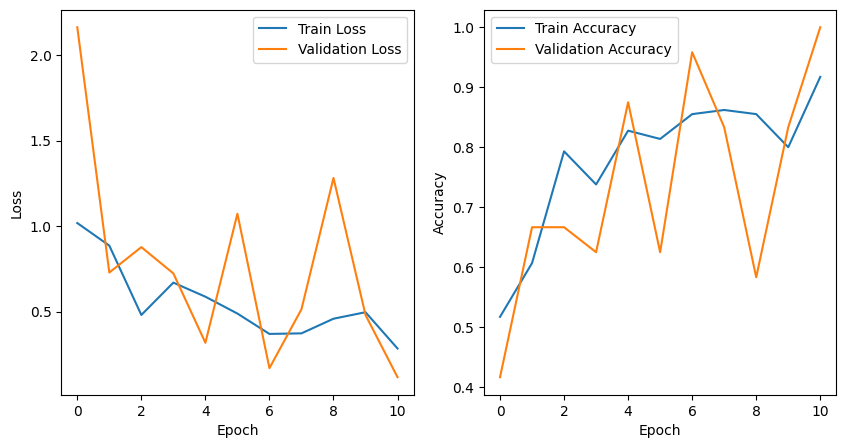

Best Epoch: None with Validation Accuracy: 1.0
Test Accuracy of the Best Model: 0.03565084636211395
Confusion Matrix of the Best Model:
 [[5 0 0]
 [0 5 0]
 [0 0 5]]


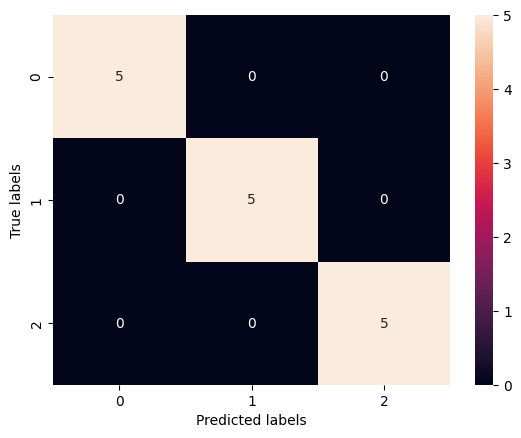

In [29]:
if __name__ == '__main__':
    use_gpu = torch.cuda.is_available()
    test_adam(args, use_gpu)
    

<h1>output handling

In [63]:
import cv2
import os
import shutil
def extract_keyframes(video_path, output_folder):
    # Open the video file
    video_capture = cv2.VideoCapture(video_path)

    # Get the total number of frames in the video
    total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"Total frames in the video: {total_frames}")

    # Initialize a list to store selected keyframes
    selected_keyframes = []

    # Parameters for keyframe selection
    num_keyframes = 30

    # Check if the total number of frames is sufficient for keyframe selection
    if total_frames > num_keyframes:
        # Open the video file for keyframe extraction
        video_capture = cv2.VideoCapture(video_path)

        # Calculate the frame skip value
        frame_skip = total_frames // num_keyframes

        # Counter for selected keyframes
        selected_frames_count = 0

        # Iterate through frames to select keyframes
        for i in range(total_frames):
            ret, frame = video_capture.read()

            if not ret:
                break

            # Select frames based on frame skip value
            if i % frame_skip == 0 and selected_frames_count < num_keyframes:
                selected_keyframes.append(frame)
                selected_frames_count += 1

        video_capture.release()

        # Print the number of frames selected
        print(f"Number of frames selected: {len(selected_keyframes)}")

        # Save the selected keyframes as a video
        video_filename = os.path.splitext(os.path.basename(video_path))[0]
        output_video_path = os.path.join(output_folder, f'{video_filename}_output_video.mp4')
        height, width, _ = selected_keyframes[0].shape
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video_writer = cv2.VideoWriter(output_video_path, fourcc, 30, (width, height))

        for keyframe in selected_keyframes:
            video_writer.write(keyframe)

        video_writer.release()

        print(f"Output video saved as: {output_video_path}")

    else:
        print("Not enough frames in the video for keyframe selection, so directly saved")
        video_filename = os.path.basename(video_path)
        output_video_path = os.path.join(output_folder, video_filename)
        shutil.copyfile(video_path, output_video_path)

# Input video file
input_video_path = r"F:\vid\bondho02_0024.mp4"

# Output folder for saving the output video
output_folder_path = r"F:\vid\newVid"

# Call the function to extract keyframes and save the output video
extract_keyframes(input_video_path, output_folder_path)


Total frames in the video: 30
Not enough frames in the video for keyframe selection.


In [64]:
#my code for marked frames+ landmarks
import dlib
import cv2
import numpy as np
import os

# Constants
VIDEO_EXTENSIONS = ('.mp4', '.avi', '.mkv')
INPUT_FOLDER = r"F:\vid\newVid"  # Input folder containing video files
OUTPUT_FOLDER = r"F:\vid\npy"  # Output folder for NumPy arrays
cropped_frames_folder=  r'F:\vid\frames'

RESIZE_DIM = (96, 96)  # Output frame size
LIP_MARGIN = 0.4  # Margin for lip-only image
# Initialize dlib's face detector and lip landmark predictor
face_detector = dlib.get_frontal_face_detector()
lip_landmark_predictor = dlib.shape_predictor(r"F:\VisualSpeech\shape_predictor_68_face_landmarks.dat")
def mark_crop_resize_gray(frame):
    # Detect faces in the frame
    faces = face_detector(frame)
    
    if len(faces) == 0:
        return None, None
    
    face = faces[0]  # Assuming there is only one face in the frame
    
    # Predict lip landmarks (20 landmarks) using the lip_landmark_predictor
    lip_landmarks = lip_landmark_predictor(frame, face)
    landmark = [(lip_landmarks.part(i).x, lip_landmarks.part(i).y) for i in range(48, 68)]
    # Create a blank grayscale image to draw lip landmarks
    marked_frame = frame.copy()

    for i in range(48, 68):
        x, y = lip_landmarks.part(i).x, lip_landmarks.part(i).y
        marked_frame[y - 3:y + 3+ 1, x - 1:x + 2] = (0, 0, 0)
        marked_frame[y - 1:y + 2, x - 3:x + 3 + 1] = (0, 0, 0)
    
    # Crop the mouth region to 256x256 size
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    roi_x = x + w // 4
    roi_y = y + h // 2
    roi_size = 256
    mouth_roi = marked_frame[roi_y:roi_y + roi_size, roi_x:roi_x + roi_size]

    # Convert the cropped mouth ROI to grayscale
    mouth_roi_gray = cv2.cvtColor(mouth_roi, cv2.COLOR_BGR2GRAY)

    # Resize the grayscale image to 256x256
    mouth_roi_gray_resized = cv2.resize(mouth_roi_gray, (98, 98))

    # Normalize the lip landmarks
    avg_x = np.mean([x for x, y in landmark])
    avg_y = np.mean([y for x, y in landmark])
    normalized_landmark = [((x - avg_x) / avg_x, (y - avg_y) / avg_y) for x, y in landmark]
    padded_normalized_landmark = np.pad(normalized_landmark, [(0, 98 - len(normalized_landmark)), (0, 0)], mode='constant') 
    
    return marked_frame, mouth_roi_gray_resized, padded_normalized_landmark

def process_video(video_path, output_folder,idxx):
    cap = cv2.VideoCapture(video_path)
    frames_with_landmarks = []
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        marked_frame, mouth_roi_gray_resized, normalized_landmark = mark_crop_resize_gray(frame)

        if marked_frame is not None:
            # Concatenate the marked frame with normalized lip landmarks
            frame_with_normalized_landmarks = np.hstack((mouth_roi_gray_resized, normalized_landmark))
            frame_with_zeros = np.vstack((frame_with_normalized_landmarks, np.zeros((2, 100))))  # Add two lines of zeros
            frames_with_landmarks.append(frame_with_zeros)
        
    for idx, frame_landmarks in enumerate(frames_with_landmarks):
        cropped_frame = frame_landmarks[:, :RESIZE_DIM[0]]  # Extract the cropped frame
        output_filename = f"cropped_frame_{idxx}.png"
        output_path = os.path.join(cropped_frames_folder, output_filename)
        cv2.imwrite(output_path, cropped_frame)
        #print(f"Saved cropped frame: {output_path}")
        idxx= idxx+1    

    cap.release()
    video_array = np.array(frames_with_landmarks)
    print("Shape of the video array:", video_array.shape)

    # Save the NumPy array in the specified output folder
    video_name = os.path.splitext(os.path.basename(video_path))[0]
    output_file = os.path.join(output_folder, f"{video_name}.npy")
    np.save(output_file, video_array)
    return video_array

def main():
    if not os.path.exists(OUTPUT_FOLDER):
        os.makedirs(OUTPUT_FOLDER)
    idxx = 0
    # Iterate through video files in the input folder
    for video_file in os.listdir(INPUT_FOLDER):
        video_path = os.path.join(INPUT_FOLDER, video_file)

        if video_file.lower().endswith(VIDEO_EXTENSIONS):
            print(f"Processing video: {video_path}")
            try:
               video_array= process_video(video_path, OUTPUT_FOLDER, idxx)
            except Exception as e:
                print(f"Error processing video {video_file}: {str(e)}")
                continue  # Move to the next video        

if __name__ == "__main__":
    main()


Processing video: F:\vid\newVid\bondho02_0024.mp4
Shape of the video array: (30, 100, 100)


In [66]:
#currently using this for adding frames and gettingsame size numpy arrray
import os
import numpy as np

numpy_folder = r'F:\vid\npy'

# Define the expected size
expected_size = (30, 100, 100)

# Get a list of all .npy files in the folder
npy_files = [f for f in os.listdir(numpy_folder) if f.endswith('.npy')]

# Sort the files to ensure they are processed in order
npy_files.sort()

# Counter for renaming
counter = 1

# Loop through each .npy file, check its size, and rename
for npy_file in npy_files:
    npy_path = os.path.join(numpy_folder, npy_file)

    # Load the NumPy array
    loaded_array = np.load(npy_path)

    # Check if the size matches the expected size
    if loaded_array.shape == expected_size:
        print(f"File {npy_file} has the correct size. Keeping it.")
    else:
        num_frames, frame_height, frame_width = loaded_array.shape
        if num_frames < 30:
            # Duplicate frames as needed
            frames_to_duplicate = 30 - num_frames
            duplicated_frames = np.repeat(loaded_array, frames_to_duplicate, axis=0)
            new_array = np.vstack((duplicated_frames, loaded_array))
            new_array = new_array[:30]  # Keep the first 30 frames

            # Save the modified NumPy array
            np.save(npy_path, new_array)
            print(f"File {npy_file} had fewer frames. Duplicated frames to reach 30.")
        elif num_frames > 30:
            # Discard extra frames from the beginning
            new_array = loaded_array[-30:]

            # Save the modified NumPy array
            np.save(npy_path, new_array)
            print(f"File {npy_file} had more frames. Discarded extra frames from the beginning.")

    # Rename the file with a numerical sequence
    new_name = f" {npy_file}"
    new_path = os.path.join(numpy_folder, new_name)
    os.rename(npy_path, new_path)
    
    # Increment the counter

    counter += 1
print("done")

File bondho02_0024.npy has the correct size. Keeping it.
done


In [67]:

def preprocess_input(input_array):
     
    
    # Assuming input_array.shape is (frames, height, width) or (height, width)
    th, tw = 90, 90  # Desired crop size
    if len(input_array.shape) == 3:
        # For (frames, height, width) array
        h, w = input_array.shape[1], input_array.shape[2]
        x1 = int(round((w - tw) / 2))
        y1 = int(round((h - th) / 2))
        input_array = input_array[:, y1:y1+th, x1:x1+tw]
    elif len(input_array.shape) == 2:
        # For (height, width) array
        h, w = input_array.shape[0], input_array.shape[1]
        x1 = int(round((w - tw) / 2))
        y1 = int(round((h - th) / 2))
        input_array = input_array[y1:y1+th, x1:x1+tw]
    input_array = ColorNormalize(input_array)

    # Add batch dimension and convert to torch tensor
    input_array = np.expand_dims(input_array, axis=0)  # Add batch dimension
    input_array = np.expand_dims(input_array, axis=0)  # Add frames dimension
    
    # Convert array to torch tensor
    preprocessed_input = torch.from_numpy(input_array).float()
    return preprocessed_input

def ColorNormalize(batch_img):
    mean = 0.413621
    std = 0.1700239
    batch_img = (batch_img - mean) / std
    return batch_img
    
def predict_single_output(model, test_data, use_gpu=False):
    model.eval()  # Set the model to evaluation mode
    with torch.no_grad():
        if use_gpu:
            test_data = test_data.cuda()
        output = model(test_data)
        _, predicted_label = torch.max(output, 1)
    return predicted_label.item()  # Return the predicted label as a scalar

if __name__ == '__main__':
    # Load the trained model
    saved_model = Lipreading(mode=args.mode, inputDim=512, hiddenDim=1024, nClasses=3, frameLen=30, every_frame=args.every_frame)
    saved_model.load_state_dict(torch.load('modelipoptest.pth'))

    # Determine if GPU is available
    use_gpu = torch.cuda.is_available()    
    input_folder = r'F:\vid\npy'
    input_file = os.listdir(input_folder)[0]  # Assuming only one file is present in the folder
    input_data = np.load(os.path.join(input_folder, input_file))
    input_data = preprocess_input(marked_frames_array)

    # Predict the single output
    predicted_label = predict_single_output(saved_model, input_data, use_gpu)

    # Print the predicted label
    print("Predicted label:", predicted_label)

Predicted label: 0


<h1> cache clear

In [ ]:
import gc
import torch
gc.collect()
torch.cuda.empty_cache()

In [ ]:
del model
gc.collect()
torch.cuda.empty_cache()